# Unmix the Signal (ICA)

**Goal:** recover clean audio sources from mixed recordings using Independent Component Analysis (ICA) implemented from scratch, with no library ICA.

**Approach in one line:** mix the sources, center the mixtures, whiten them with PCA, run FastICA to find the unmixing matrix, export the separated audio, and compare with the originals.

**Files:** `speech.wav` and `music.wav` (the clean sources, links in the README). The notebook writes `mixed_mic1.wav`, `mixed_mic2.wav`, `separated_source1.wav` and `separated_source2.wav`.

**How to run:** restart the kernel and run all cells in order.

## Step 1: Choose sources and mix them

Each source is loaded, made mono and scaled to the range -1 to 1. If the two files have different sample rates, the second is resampled to match the first, so both sounds play at their true speed. The sources are trimmed to the same length and stacked into a table `S` with one row per source.

I then mix them with my own mixing matrix `A`:

**x = A · s**

Here `s` holds the sources, `A` says how much of each source reaches each microphone, and `x` are the mixed recordings. With N sources I need at least N mixtures, and my 2 sources give 2 mixtures.

In [1]:
import numpy as np
import scipy.io.wavfile as wav
from math import gcd
from scipy.signal import resample_poly

def load_unaltered(filepath):
    sr, data = wav.read(filepath)
    if data.ndim > 1:
        data = data.mean(axis=1)
    data = data.astype(np.float32)
    max_val = np.max(np.abs(data))
    if max_val > 0:
        data = data / max_val
    return sr, data

files = ["speech.wav", "music.wav"]   # add or remove files here
n_src = len(files)

sources, sr = [], None
for f in files:
    r, d = load_unaltered(f)
    if sr is None:
        sr = r
    elif r != sr:
        print(f"{f} is {r} Hz, resampling to {sr} Hz")
        g_ = gcd(sr, r)
        d = resample_poly(d, sr // g_, r // g_)
        d = d / np.max(np.abs(d))
    sources.append(d)

min_len = min(len(d) for d in sources)
S = np.stack([d[:min_len] for d in sources])

if n_src == 2:
    A = np.array([[0.6, 0.4],
                  [0.3, 0.7]])
else:
    rng = np.random.RandomState(42)
    while True:
        A = rng.uniform(0.2, 1.0, size=(n_src, n_src))
        if np.linalg.cond(A) < 30:
            break

X = np.dot(A, S)

for i in range(n_src):
    wav.write(f"mixed_mic{i+1}.wav", sr, (X[i] / np.max(np.abs(X[i]))).astype(np.float32))

print(f"Mixed {n_src} sources. Duration: {min_len / sr:.2f} s at {sr} Hz. Mixing matrix condition number: {np.linalg.cond(A):.1f}")

music.wav is 44100 Hz, resampling to 48000 Hz
Mixed 2 sources. Duration: 69.67 s at 48000 Hz. Mixing matrix condition number: 3.4


## Step 2: Center the mixed signals and whiten with PCA

**Centering:** subtract each signal's average, so every signal wobbles around zero.

**Whitening:** I compute the covariance matrix of the centered data and find its eigenvalues and eigenvectors with eigendecomposition. The whitening matrix is **D^(-1/2) · Eᵀ**, where E holds the eigenvectors and D the eigenvalues. It first rotates the data onto its main directions and then rescales each direction to variance 1.

**Check:** the covariance of the whitened data should be the identity matrix, with 1 on the diagonal and 0 elsewhere. The output below confirms this.

**Why this helps:** after whitening the signals are uncorrelated and have equal spread, so the only thing left for ICA to find is a rotation. That is a much smaller search than finding a full unknown matrix.

In [2]:
# 1. Center the data (subtract the mean of each row)
X_mean = np.mean(X, axis=1, keepdims=True)
X_centered = X - X_mean

# 2. Calculate the covariance matrix
N = X_centered.shape[1]
cov_matrix = np.dot(X_centered, X_centered.T) / N

# 3. PCA Whitening using eigendecomposition
# Get eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Calculate the whitening matrix: D^(-1/2) * E^T
D_inv_sqrt = np.diag(1.0 / np.sqrt(eigenvalues))
W_white = np.dot(D_inv_sqrt, eigenvectors.T)

# 4. Apply the whitening matrix to the centered data
X_whitened = np.dot(W_white, X_centered)

# Verify the math: the new covariance matrix should be an Identity Matrix
print("Covariance matrix of whitened data:\n", np.round(np.cov(X_whitened), decimals=5))

Covariance matrix of whitened data:
 [[1. 0.]
 [0. 1.]]


## Step 3: FastICA from scratch

FastICA looks for directions in the whitened data where the signal is as non-Gaussian (as un-bell-shaped) as possible. For each direction `w` it repeats:

1. Compute the current estimates `w·z`.
2. Update: **w ← E[z · g(wᵀz)] − E[g′(wᵀz)] · w**, with g = tanh and g′ = 1 − tanh².
3. Decorrelate all directions together (symmetric decorrelation, `W ← (W Wᵀ)^(-1/2) W`) so two directions cannot lock onto the same source.
4. Stop when the directions no longer change.

The result is the unmixing matrix `W`, and the separated signals are `W` times the whitened data. They are exported as `.wav` files.

In [3]:
def g(x):
    return np.tanh(x)

def g_prime(x):
    return 1.0 - np.tanh(x)**2

def fastICA(Z, n_components, max_iter=200, tol=1e-5, seed=42):
    n_samples = Z.shape[1]
    rng = np.random.RandomState(seed)
    W = rng.randn(n_components, n_components)
    U, sing, Vh = np.linalg.svd(W)
    W = U @ Vh                                   # start from an orthogonal matrix

    for i in range(max_iter):
        estimates = np.dot(W, Z)
        term1 = np.dot(g(estimates), Z.T) / n_samples
        term2 = np.mean(g_prime(estimates), axis=1, keepdims=True) * W
        W_new = term1 - term2

        U, sing, Vh = np.linalg.svd(W_new)       # symmetric decorrelation
        W_new = np.dot(U, np.dot(np.diag(1.0 / sing), U.T)) @ W_new

        distance = np.max(np.abs(np.abs(np.diag(np.dot(W_new, W.T))) - 1))
        W = W_new
        if distance < tol:
            print(f"Algorithm converged successfully at iteration {i}!")
            break
    else:
        print("Warning: did not converge within max_iter")
    return W

W_unmix = fastICA(X_whitened, n_components=n_src)
S_estimated = np.dot(W_unmix, X_whitened)

for i in range(n_src):
    wav.write(f"separated_source{i+1}.wav", sr, (S_estimated[i] / np.max(np.abs(S_estimated[i]))).astype(np.float32))
print("Saved separated_source1.wav to", f"separated_source{n_src}.wav")

Algorithm converged successfully at iteration 2!
Saved separated_source1.wav to separated_source2.wav


## Step 4: Evaluate against the originals

ICA has two built-in ambiguities that I have to handle before scoring:

- **Permutation:** the outputs can come out in a different order than the sources. I match each original to its best estimate using absolute correlation, with each estimate used only once.
- **Scale and sign:** ICA cannot know the original loudness or whether a wave is upside-down. For each matched pair I find the best scaling factor α (which can be negative) and compare the original with α times the estimate.

**Metrics:**

- **Correlation** (from 0 to 1 in absolute value) says whether the recovered signal has the same shape as the original.
- **SDR** (signal-to-distortion ratio, in dB) = 10 · log10( energy of the original / energy of the error ). Higher is cleaner. Roughly, 10 dB is acceptable and 20 dB or more is very good. I chose it because it is the common score for audio separation and it also counts leftover leakage from the other source.

**PCA versus ICA:** I score the PCA-whitened signals the same way, to show what whitening alone achieves.

**Results (2 sources, no noise):**

| Method | Speech | Music |
|---|---|---|
| ICA correlation | 1.0000 | 1.0000 |
| ICA SDR | 48.5 dB | 53.0 dB |
| PCA-only correlation | 0.79 | 0.80 |
| PCA-only SDR | 4.3 dB | 4.4 dB |

ICA gives one clean source in each output. After PCA alone, each output is still a blend of both sources, with correlations of about 0.8 to one source and 0.6 to the other. The near-perfect ICA scores are expected here because the mixing is exactly linear and has no noise.

In [4]:
from scipy.optimize import linear_sum_assignment

def evaluate(S_true, S_est):
    n = S_true.shape[0]
    S_c = S_true - S_true.mean(axis=1, keepdims=True)
    corr = np.abs(np.corrcoef(S_c, S_est)[:n, n:])
    rows, cols = linear_sum_assignment(-corr)          # fixes the order swap
    results, aligned = [], np.zeros_like(S_c)
    for i, j in zip(rows, cols):
        y = S_est[j]
        alpha = np.dot(S_c[i], y) / np.dot(y, y)       # fixes sign and loudness
        aligned[i] = alpha * y
        sdr = 10 * np.log10(np.sum(S_c[i]**2) / np.sum((S_c[i] - alpha * y)**2))
        results.append((i, j, corr[i, j], sdr))
    return corr, results, aligned

def show(name, S_true, S_est, names):
    corr, results, aligned = evaluate(S_true, S_est)
    print(f"--- {name} ---")
    print("Absolute correlation matrix (rows = originals, columns = estimates):\n", np.round(corr, 4))
    for i, j, c, sdr in results:
        print(f"{names[i]} <-> estimate {j+1}: correlation {c:.4f}, SDR {sdr:.1f} dB")
    return aligned

names = [f.replace(".wav", "") for f in files]
S_aligned = show("ICA", S, S_estimated, names)
_ = show("PCA whitening only (no ICA)", S, X_whitened, names)

--- ICA ---
Absolute correlation matrix (rows = originals, columns = estimates):
 [[1.     0.0038]
 [0.0022 1.    ]]
speech <-> estimate 1: correlation 1.0000, SDR 48.5 dB
music <-> estimate 2: correlation 1.0000, SDR 53.0 dB
--- PCA whitening only (no ICA) ---
Absolute correlation matrix (rows = originals, columns = estimates):
 [[0.7944 0.6074]
 [0.6026 0.798 ]]
speech <-> estimate 1: correlation 0.7944, SDR 4.3 dB
music <-> estimate 2: correlation 0.7980, SDR 4.4 dB


## Step 5: Plots

The left column shows the original sources, the middle column shows the mixed microphone signals, and the right column shows the recovered signal drawn on top of the original. The recovered signal has been matched, flipped and rescaled as described in Step 4. A short 50 ms window is plotted so that the waves are visible. The red recovered line follows the gray original closely, which agrees with the high SDR.

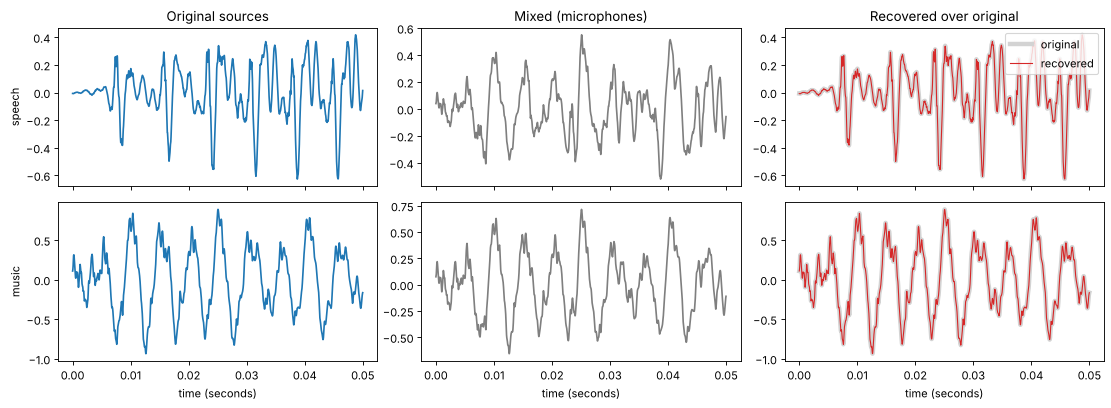

In [5]:
import matplotlib.pyplot as plt

n_show = int(0.05 * sr)                  # 50 milliseconds, so the waves are visible
t = np.arange(n_show) / sr
S_c = S - S.mean(axis=1, keepdims=True)

# pick the 50 ms window where every source is active (avoids silent gaps)
n_win = S_c.shape[1] // n_show
rms = np.array([[np.sqrt(np.mean(S_c[i, w*n_show:(w+1)*n_show]**2)) for w in range(n_win)] for i in range(n_src)])
start = int(np.argmax(np.min(rms / rms.max(axis=1, keepdims=True), axis=0))) * n_show

fig, axs = plt.subplots(n_src, 3, figsize=(14, 2.6 * n_src), sharex=True)
axs = np.atleast_2d(axs)
for i in range(n_src):
    axs[i, 0].plot(t, S_c[i, start:start+n_show], color="tab:blue")
    axs[i, 0].set_ylabel(names[i])
    axs[i, 1].plot(t, X_centered[i, start:start+n_show], color="tab:gray")
    axs[i, 2].plot(t, S_c[i, start:start+n_show], color="lightgray", linewidth=4, label="original")
    axs[i, 2].plot(t, S_aligned[i, start:start+n_show], color="tab:red", linewidth=1, label="recovered")
    if i == 0:
        axs[i, 0].set_title("Original sources")
        axs[i, 1].set_title("Mixed (microphones)")
        axs[i, 2].set_title("Recovered over original")
        axs[i, 2].legend(loc="upper right")
for ax in axs[-1]:
    ax.set_xlabel("time (seconds)")
plt.tight_layout()
plt.show()

## Experiment: separation quality at different noise levels

Real recordings contain noise, so I added Gaussian noise to the mixed signals at signal-to-noise ratios (SNR) from 40 dB (very clean) down to 0 dB (noise as loud as the sound). For each level I ran the same pipeline and measured the average SDR for ICA and for PCA whitening alone.

| SNR | ICA SDR | PCA-only SDR |
|---|---|---|
| 40 dB | 34.6 dB | 4.4 dB |
| 30 dB | 24.7 dB | 4.3 dB |
| 20 dB | 14.9 dB | 4.1 dB |
| 10 dB | 6.5 dB | 3.1 dB |
| 5 dB | 3.6 dB | 2.3 dB |
| 0 dB | 1.9 dB | 1.4 dB |

**What the results show:**

- PCA stays near 4 dB at every noise level because it never separates the sources.
- ICA improves steadily as the recordings get cleaner. Between 40 dB and 10 dB SNR, its SDR comes out roughly 4 to 5 dB below the recording SNR.
- At 0 dB SNR the two methods are close, so noise this strong limits both.

SNR 40 dB -> ICA SDR  34.6 dB, PCA-only SDR   4.4 dB
SNR 30 dB -> ICA SDR  24.7 dB, PCA-only SDR   4.3 dB
SNR 20 dB -> ICA SDR  14.9 dB, PCA-only SDR   4.1 dB
SNR 10 dB -> ICA SDR   6.5 dB, PCA-only SDR   3.1 dB
SNR  5 dB -> ICA SDR   3.6 dB, PCA-only SDR   2.3 dB
SNR  0 dB -> ICA SDR   1.9 dB, PCA-only SDR   1.4 dB


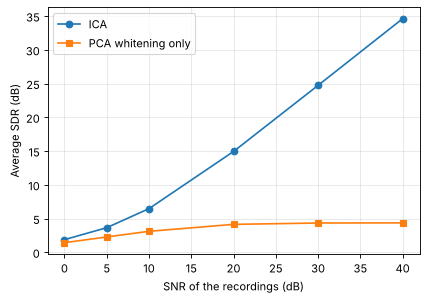

In [6]:
import io, contextlib

def separate(Xin, n_components):
    Xc = Xin - Xin.mean(axis=1, keepdims=True)
    cov = np.dot(Xc, Xc.T) / Xc.shape[1]
    vals, vecs = np.linalg.eigh(cov)
    order = np.argsort(vals)[::-1][:n_components]
    vals, vecs = vals[order], vecs[:, order]
    Zw = np.diag(1.0 / np.sqrt(vals)) @ vecs.T @ Xc
    W = fastICA(Zw, n_components=n_components)
    return W @ Zw, Zw

snr_list = [40, 30, 20, 10, 5, 0]
ica_sdr, pca_sdr = [], []
noise_rng = np.random.RandomState(0)

for snr in snr_list:
    Xn = np.zeros_like(X)
    for k in range(X.shape[0]):
        noise_power = np.mean(X[k]**2) / (10 ** (snr / 10))
        Xn[k] = X[k] + noise_rng.randn(X.shape[1]) * np.sqrt(noise_power)
    with contextlib.redirect_stdout(io.StringIO()):
        S_ica, S_pca = separate(Xn, n_src)
    ica_sdr.append(np.mean([r[3] for r in evaluate(S, S_ica)[1]]))
    pca_sdr.append(np.mean([r[3] for r in evaluate(S, S_pca)[1]]))
    print(f"SNR {snr:>2} dB -> ICA SDR {ica_sdr[-1]:5.1f} dB, PCA-only SDR {pca_sdr[-1]:5.1f} dB")

plt.figure(figsize=(6, 4))
plt.plot(snr_list, ica_sdr, "o-", label="ICA")
plt.plot(snr_list, pca_sdr, "s-", label="PCA whitening only")
plt.xlabel("SNR of the recordings (dB)")
plt.ylabel("Average SDR (dB)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Bonus: real recordings from multiple devices

Here the mixing is done by a real room instead of my own matrix. The same speech and music files are played from two sources in a room, and two or more devices (for example phones) record at the same time. The devices start recording at slightly different moments and may use different sample rates, so the recordings are first resampled to a common rate and aligned in time with cross-correlation. Then the same centering, whitening and FastICA pipeline is applied.

Because I know which clean files were played, I can score the result: for each original file I compute the peak normalized cross-correlation (which allows for a small time delay) with every separated output, and with every raw phone recording for comparison. If ICA worked, each original should match one separated output clearly better than it matches any raw recording.

A real room adds echoes and delays that the simple model `x = A · s` does not include, so I expect this to be less clean than the synthetic results above.

The code below runs only if `phone1.wav` and `phone2.wav` are in the folder.

In [7]:
import os
from scipy.signal import correlate

def load_device_recordings(device_files, target_sr=None, max_seconds=None):
    recs, srs = [], []
    for f in device_files:
        r, d = load_unaltered(f)
        srs.append(r); recs.append(d)
    target_sr = target_sr or min(srs)
    out = []
    for r, d in zip(srs, recs):
        if r != target_sr:
            g_ = gcd(target_sr, r)
            d = resample_poly(d, target_sr // g_, r // g_)
        if max_seconds:
            d = d[: int(max_seconds * target_sr)]
        out.append(d - d.mean())
    return target_sr, out

def align_devices(recs, sr, max_lag_seconds=3.0, probe_seconds=20):
    ref = recs[0]
    n_probe = int(probe_seconds * sr)
    max_lag = int(max_lag_seconds * sr)
    aligned, lags = [ref], [0]
    for other in recs[1:]:
        a = ref[:n_probe]; b = other[:n_probe]
        c = correlate(a, b, mode="full", method="fft")
        lags_axis = np.arange(-len(b) + 1, len(a))
        keep = np.abs(lags_axis) <= max_lag
        lag = int(lags_axis[keep][np.argmax(np.abs(c[keep]))])
        if lag > 0:
            shifted = np.concatenate([np.zeros(lag), other])
        else:
            shifted = other[-lag:]
        aligned.append(shifted); lags.append(lag)
    L = min(len(x) for x in aligned)
    return np.stack([x[:L] for x in aligned])[:, max(0, max(lags)):], lags

def peak_xcorr(a, b, sr, max_lag_s=5.0, seconds=20):
    # similarity of a and b that allows a small time delay (1.0 = identical shape)
    n = int(seconds * sr)
    a = a[:n] - a[:n].mean(); b = b[:n] - b[:n].mean()
    c = correlate(a, b, mode="full", method="fft")
    lags = np.arange(-len(b) + 1, len(a))
    keep = np.abs(lags) <= int(max_lag_s * sr)
    return np.max(np.abs(c[keep])) / (np.linalg.norm(a) * np.linalg.norm(b))

phone_files = ["phone1.wav", "phone2.wav"]       # recordings of the same room, made at the same time
if all(os.path.exists(f) for f in phone_files):
    real_sr, real_recs = load_device_recordings(phone_files)
    X_real, lags = align_devices(real_recs, real_sr)
    print("Common sample rate:", real_sr, "Hz")
    print("Time offsets found (seconds):", [round(l / real_sr, 3) for l in lags])

    S_real, _ = separate(X_real, n_components=X_real.shape[0])
    for i in range(S_real.shape[0]):
        wav.write(f"real_separated_{i+1}.wav", real_sr, (S_real[i] / np.max(np.abs(S_real[i]))).astype(np.float32))
    print("Saved real_separated_1.wav ...")

    # the clean files that were played in the room are the ground truth
    originals = []
    for f in files:
        r, d = load_unaltered(f)
        if r != real_sr:
            g_ = gcd(real_sr, r)
            d = resample_poly(d, real_sr // g_, r // g_)
        originals.append(d)
    ica_scores = np.array([[peak_xcorr(S_real[j], originals[i], real_sr) for j in range(S_real.shape[0])] for i in range(len(originals))])
    raw_scores = np.array([[peak_xcorr(X_real[j], originals[i], real_sr) for j in range(X_real.shape[0])] for i in range(len(originals))])
    print("\nSimilarity with the played files (rows = originals):")
    print("Raw phone recordings (columns = phones):\n", np.round(raw_scores, 3))
    print("ICA outputs (columns = outputs):\n", np.round(ica_scores, 3))
    for i, name in enumerate(names):
        print(f"{name}: best raw phone {raw_scores[i].max():.3f}, best ICA output {ica_scores[i].max():.3f}")
else:
    print("Skipping: record the room on 2 devices and save them as", phone_files)

Skipping: record the room on 2 devices and save them as ['phone1.wav', 'phone2.wav']


## Stretch: mini-Shazam

Each song is turned into a spectrogram and only the loudest peaks are kept. Pairs of nearby peaks become fingerprints (the two frequencies and the time gap between them). To identify a clip, its fingerprints are looked up in a library of 5 to 10 songs, and every match votes for a song and a time offset. The song with the most votes at one consistent offset is the answer.

I test it on clips of the ICA-separated music, and on the raw mixed microphones for comparison.

The code below runs only if all the song files in `song_files` are in the folder.

In [8]:
from scipy.signal import spectrogram
from scipy.ndimage import maximum_filter
from collections import defaultdict, Counter

FP_SR = 8000

def to_fp_rate(x, sr_in):
    g_ = gcd(FP_SR, sr_in)
    y = resample_poly(x, FP_SR // g_, sr_in // g_)
    return y - y.mean()

def find_peaks(x, nperseg=1024, neighborhood=(21, 21), min_db_above_floor=18.0):
    f, t, Sxx = spectrogram(x, fs=FP_SR, nperseg=nperseg, noverlap=nperseg // 2)
    L = 10 * np.log10(Sxx + 1e-12)
    local_max = (L == maximum_filter(L, size=neighborhood))
    keep = local_max & (L > np.median(L) + min_db_above_floor)
    fi, ti = np.nonzero(keep)
    order = np.argsort(ti)
    return fi[order], ti[order]

def make_hashes(fi, ti, fan_out=6, dt_min=1, dt_max=60):
    hashes = []
    for k in range(len(ti)):
        c = 0
        for m in range(k + 1, len(ti)):
            dt = ti[m] - ti[k]
            if dt < dt_min: continue
            if dt > dt_max: break
            hashes.append(((int(fi[k]), int(fi[m]), int(dt)), int(ti[k])))
            c += 1
            if c >= fan_out: break
    return hashes

class MiniShazam:
    def __init__(self):
        self.db = defaultdict(list)
        self.song_names = []
    def add_song(self, name, x, sr_in):
        sid = len(self.song_names); self.song_names.append(name)
        fi, ti = find_peaks(to_fp_rate(x, sr_in))
        for h, t0 in make_hashes(fi, ti):
            self.db[h].append((sid, t0))
    def identify(self, clip, sr_in):
        fi, ti = find_peaks(to_fp_rate(clip, sr_in))
        votes = Counter()
        for h, tq in make_hashes(fi, ti):
            for sid, tdb in self.db.get(h, ()):
                votes[(sid, tdb - tq)] += 1
        scores = np.zeros(len(self.song_names))
        for (sid, off), v in votes.items():
            scores[sid] = max(scores[sid], v)
        best = int(np.argmax(scores)) if scores.max() > 0 else -1
        return best, scores

# Library of 5 to 10 songs (music.wav should be one of them)
song_files = ["music.wav", "song2.wav", "song3.wav", "song4.wav", "song5.wav"]
missing = [f for f in song_files if not os.path.exists(f)]
if missing:
    print("Skipping: these song files are not in the folder yet:", missing)
else:
    shazam = MiniShazam()
    for f in song_files:
        r, d = load_unaltered(f)
        shazam.add_song(f, d, r)
    print("Library:", shazam.song_names)

    def try_identify(label, clip, sr_clip):
        best, scores = shazam.identify(clip, sr_clip)
        name = shazam.song_names[best] if best >= 0 and scores[best] >= 10 else "no confident match"
        print(f"{label}: best match = {name}, scores = {scores.astype(int)}")

    seg = slice(5 * sr, 15 * sr)                      # a 10 second clip
    for k in range(n_src):
        try_identify(f"ICA output {k+1}", S_estimated[k][seg], sr)
    for k in range(X.shape[0]):
        try_identify(f"Mixed mic {k+1} (no ICA)", X[k][seg], sr)
    if "S_real" in globals():
        seg_r = slice(5 * real_sr, 15 * real_sr)
        for k in range(S_real.shape[0]):
            try_identify(f"Real-room ICA output {k+1}", S_real[k][seg_r], real_sr)

Skipping: these song files are not in the folder yet: ['song2.wav', 'song3.wav', 'song4.wav', 'song5.wav']


## Summary and answers to the key questions

**1. Why ICA over PCA?**
PCA only uses second-order statistics (covariances), so it can make signals uncorrelated but cannot find the sources. Uncorrelated is weaker than independent. ICA also uses higher-order statistics, which describe the shape of the data, to find the rotation that makes the outputs statistically independent. My results show this: PCA alone gave about 4 dB SDR, while ICA gave about 50 dB.

**2. What does whitening do and why does it simplify ICA?**
Whitening makes the mixed signals uncorrelated with equal variance, so their covariance becomes the identity. After that, the only unknown left is a rotation, which ICA can search for much more easily than a full mixing matrix.

**3. Why does non-Gaussianity enable separation, and how does the Central Limit Theorem relate?**
The Central Limit Theorem says a sum of independent variables looks closer to a Gaussian than the variables themselves. A mixture is a sum of sources, so mixtures are more Gaussian than the sources. Searching for the directions that are least Gaussian therefore leads back to the sources. This only works if at most one source is Gaussian, because Gaussian data looks the same in every rotation.

**4. How were the experiments and metrics chosen?**
Correlation is simple and shows whether the shape matches. SDR is the standard audio-separation score and also counts leakage between sources. Both are computed after fixing the order, sign and scale. The noise experiment tests how robust the method is, and the PCA comparison shows why ICA is needed.

**Limitations:** the main experiment uses exactly linear mixing without echo or noise, so near-perfect scores are expected. Real recordings will give lower scores.